# NumPy — dimensions, image, and audio exercises

Behavioural data contain three invented sessions of 40 trials each. Explain what each axis represents before computing summaries. Then use NumPy to crop and process images and sound.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Exercise 1: one accuracy per session

Inspect the array shape. Select the second session and the first five trials of the third session. Calculate accuracy for every session with one NumPy call, then decide which sessions satisfy **accuracy > 0.66**. Check one session by hand. Plot session accuracy with labels.

In [1]:
session_outcomes = np.array([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

In [1]:
# Select, summarise, check, and plot.

## Exercise 2: diagnose the wrong axis

A classmate wants one accuracy for each of the three sessions but uses `np.mean(session_outcomes, axis=0)`. Predict the output shape, then run it. Explain what those values summarise. Repair the call and verify its output length.

**Work backwards:** which axis would you use to calculate one correct-response count per trial position?

In [1]:
# Inspect the wrong-axis result, repair it, and answer the reverse task.

**Your explanation:** which dimension disappears in each summary, and what does one output value represent?

## Exercise 3: cut out a face

The supplied RGB image shows astronaut Eileen Collins. Run the loading and display cell. Inspect `image.shape`.

The face lies in this **region of interest (ROI)**, measured in original-image pixels from the top left:
- horizontal range: **170 ≤ x < 290**;
- vertical range: **50 ≤ y < 190**.

Use array slicing to cut out the face and store it as `face`. Plot the cropped image. Keep all three colour channels. Predict and check the crop shape: how many rows, columns, and channels should remain? Explain why the row slice comes before the column slice.

(512, 512, 3)


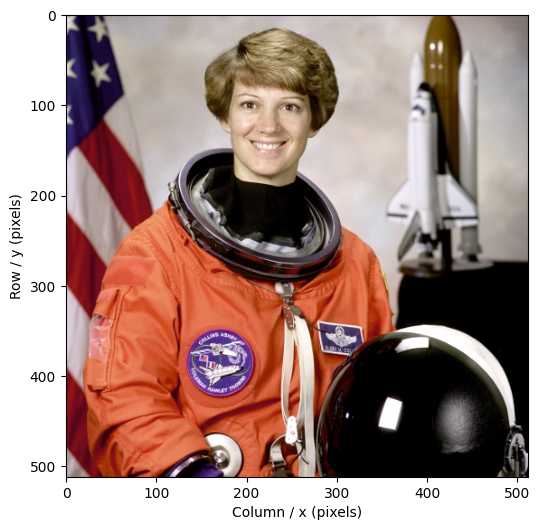

In [1]:
image = plt.imread("assets/astronaut.png")
print(image.shape)
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.xlabel("Column / x (pixels)")
plt.ylabel("Row / y (pixels)")
plt.show()

In [1]:
# Slice image into face and plot the cropped face.

## Exercise 4: RGB to grayscale

Load `assets/astronaut.png` into a new variable called `rgb_image` using `plt.imread`. The channel order is red, green, blue; the loaded values lie between 0 and 1.

1. Predict the shape of a grayscale image with the same height and width.
2. Create `gray_image` by **averaging over the three colour channels** with `np.mean` and the appropriate `axis`. Do not use a conversion library or a loop.
3. Plot it using `plt.imshow(gray_image, cmap="gray", vmin=0, vmax=1)`.
4. Check the shape and calculate the grayscale value at pixel `[100, 200]` from its three input values.
5. Explain why averaging over rows instead would not produce the requested image.

Optional: make a grayscale crop of the same face ROI. This exercise uses a simple arithmetic mean rather than a brightness-weighted conversion.

In [1]:
# Load RGB, reduce the channel axis, plot, and check a pixel.

**Your explanation:** which axis did you average over? What dimensions remain? Why is displaying the original RGB array with `cmap="gray"` insufficient to perform the conversion?

## Exercise 5: isolate one fly by thresholding

`assets/fly.png` shows a **real Drosophila melanogaster photographed from above with its wings lying flat over the abdomen**, placed on a larger, plain chamber background for this exercise. Use a brightness threshold to isolate its body and find it within the chamber.

1. Load the image using `fly_image = plt.imread("assets/fly.png")` and inspect its shape. This PNG loads with RGB values between 0 and 1, as in the earlier image exercises. Plot the original colour image.
2. Reuse your approach from Exercise 4 to create a two-dimensional grayscale image. Inspect its minimum and maximum values with `np.min` and `np.max`.
3. Choose a brightness threshold and make a Boolean mask called `fly_mask`, with `True` for dark fly pixels and `False` for the light background. Because the fly is dark, select pixels **below** the brightness threshold. Use NumPy, without a loop.
4. Plot the mask with `plt.imshow(fly_mask, cmap="gray", vmin=0, vmax=1)`. White should mark selected fly pixels. Compare it with the original: does the background disappear, and is the body retained?
5. Try a lower and a higher threshold. Describe what is lost or added, then choose the threshold you think best isolates the body.
6. Check that the mask has the same height and width as the original, with no colour-channel dimension. Inspect one background pixel and one body pixel to check your selection.

The aim is an approximate body mask. Thin legs, translucent wings, and lighter parts of the body may not all be selected. This is a brightness rule, not recognition of a fly.

*Photographic source:* Nicola White and Tom A. R. Price, *Drosophila melanogaster* photography collection (2021), University of Liverpool, [DOI: 10.17638/datacat.liverpool.ac.uk/1561](https://doi.org/10.17638/datacat.liverpool.ac.uk/1561), [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/). The dorsal male photograph was resized and its background digitally extended with an image-editing model to make this teaching composite. It is not an unedited chamber recording. The source photograph is included as `assets/fly_source.png`.


In [1]:
# Load the single-fly image, convert it to grayscale, and make and plot fly_mask.
# Compare three thresholds and check the mask shape and two pixels.


**Your explanation:** What does `np.sum(fly_mask)` count? Why does this number measure selected area rather than the number of flies?


### Optional: find the fly's position

Use the coordinates of the selected pixels to estimate one position for the fly. The following line returns the row and column indices where the mask is `True`:

```python
rows, columns = np.nonzero(fly_mask)
```

1. Run that line and inspect `rows.shape` and `columns.shape`. How do their lengths relate to `np.sum(fly_mask)`? Check that you selected at least one pixel before computing a position.
2. Calculate the **mean row** and **mean column** with `np.mean`. These give the centre of the selected pixels. Alternatively, use `np.median` for each coordinate. Use NumPy, without a loop.
3. Plot the **original colour image**, then overlay the estimated position as a red dot with `plt.scatter(x_position, y_position, color="red", s=60)`. Remember: **x is the column; y is the row**. Do not transpose or flip the image.
4. Does the dot fall on the fly's body? Try another threshold. If time permits, compare the mean and median estimates.

**Explain:** Why can changing the threshold move the dot? Is the centre of the selected pixels necessarily an anatomical landmark such as the head or the centre of the thorax?


In [1]:
# Get the selected row and column indices.
# Compute their mean or median and overlay the resulting position on the image.


## Exercise 6: crop speech

An image is an array of pixels. A mono sound recording is a one-dimensional array of **samples**: each value describes the sound pressure at one instant. The **sample rate** tells you how many samples were recorded per second.

Use NumPy operations without loops. Loading and playback code are supplied; write the slicing yourself. Amplitude compression in Part 2 is optional.

### 0. Load and listen — supplied code

Run the cell below. `scipy.io.wavfile.read` loads a WAV file and returns the sample rate and a NumPy array. This supplied file is **mono, 16-bit signed PCM**. Dividing by 32768 converts its integer samples to floating-point values between −1 and 1 for processing and playback. This divisor is specific to this file format.

`IPython.display.Audio` creates a player in the notebook. Click its play button. The recording contains two spoken sentences, with silence between them. Start with a comfortable playback volume.


In [1]:
from scipy.io import wavfile
from IPython.display import Audio, display

sample_rate, audio_int = wavfile.read("assets/speech.wav")
audio = audio_int.astype(float) / 32768

print("Sample rate:", sample_rate, "samples per second")
print("Array shape:", audio.shape)
print("Duration:", len(audio) / sample_rate, "seconds")
display(Audio(audio, rate=sample_rate, normalize=False))


Sample rate: 16000 samples per second
Array shape: (208000,)
Duration: 13.0 seconds


### 1. Cut out one sentence

Extract only the second sentence:

> Nor is Mister Quilter's manner less interesting than his matter.

Use the interval **7.0 ≤ time < 12.0 seconds**, which includes a little silence around the sentence.

1. Convert the start and stop times to integer sample indices: `sample index = int(time_in_seconds * sample_rate)`.
2. Use one array slice to store the cut audio as `sentence`.
3. Predict and check its shape and duration. Should the slice contain 5 values or 80,000 values?
4. Play your crop using the code below and check that it contains the complete target sentence and none of the first sentence.

```python
display(Audio(sentence, rate=sample_rate, normalize=False))
```

**Connect to the image crop:** why do you need only one slice for mono audio, but row and column slices for an image?


In [1]:
start_seconds = 7.0
stop_seconds = 12.0

# Convert seconds to sample indices and slice audio into sentence.
# Check the shape and duration, then play the sentence.


### 2. Optional: compress the amplitude and compare before/after

**Amplitude compression** reduces the contrast between small and large sample magnitudes. It leaves the number of samples and sample rate unchanged, so the sentence keeps its duration. It does not make a smaller audio file.

A plain `np.log(sentence)` will not work: samples can be negative or zero. Instead, apply the log to the **magnitude**, adding 1 so that silence stays well defined, and then restore the original sign.

For each input sample $x$, use

$$y = \operatorname{sign}(x)\,\frac{\log(1 + k\,|x|)}{\log(1 + k)}.$$

Here, `k` controls the strength. Start with **k = 20**. The denominator keeps the output between −1 and 1 when the input is in that range.

Useful NumPy functions, all applied element by element:

| Function | Meaning | Example |
| --- | --- | --- |
| `np.abs(x)` | Magnitude | `np.abs(-0.2)` → `0.2` |
| `np.sign(x)` | −1, 0, or +1 | `np.sign(-0.2)` → `-1` |
| `np.log(x)` | Natural logarithm | `np.log(1)` → `0.0` |

1. Translate the formula into a NumPy expression and store the result as `compressed`. Use array operations, without a loop.
2. Check that its shape equals `sentence.shape`, that zero stays zero, and that positive and negative samples keep their signs. Try the formula on `np.array([-1.0, -0.1, 0.0, 0.1, 1.0])` to see its effect.
3. Copy and run the comparison code below. Keep the same device volume for both players. `normalize=False` prevents each player from automatically rescaling its input.
4. Compare **k = 5** and **k = 100** as well. What happens to quiet details, loudness, and the character of the voice?

```python
print("Before")
display(Audio(sentence, rate=sample_rate, normalize=False))
print("After")
display(Audio(compressed, rate=sample_rate, normalize=False))
```

This simple sample-by-sample transform boosts small magnitudes relative to large ones. It can make the sound louder and change its timbre or introduce distortion; it is not a transparent studio compressor.


In [1]:
k = 20

# Apply the sign-preserving log transform to sentence.
# Check the result and compare before/after playback.


**Optional explanation:** Why is taking `np.log` of the original waveform unsuitable? Why do we keep the sign? Which properties of the recording change, and which stay the same?

*Audio source:* LibriSpeech clips `1272-128104-0000` and `1272-128104-0001`, compiled by Vassil Panayotov with assistance from Daniel Povey, from LibriVox recordings. [LibriSpeech / OpenSLR 12](https://www.openslr.org/12/), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The supplied WAV joins the clips with silence; see `assets/README.md` for provenance.
